## Research Question: Are property prices in Mexico more influenced by property size or by location?

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Define the path to the clean CSV file saved in Notebook 1
data_path = "./data/mexico-real-estate-combined-clean.csv"

In [3]:
# Load the data
df = pd.read_csv(data_path)

# Verify the load
print(f"Dimensions: {df.shape[0]} rows and {df.shape[1]} columns.")
print(df.info())
df.head()

Dimensions: 1736 rows and 6 columns.
<class 'pandas.DataFrame'>
RangeIndex: 1736 entries, 0 to 1735
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   property_type  1736 non-null   str    
 1   state          1736 non-null   str    
 2   lat            1736 non-null   float64
 3   lon            1736 non-null   float64
 4   area_m2        1736 non-null   float64
 5   price_usd      1736 non-null   float64
dtypes: float64(4), str(2)
memory usage: 112.8 KB
None


,property_type,state,lat,lon,area_m2,price_usd
0,house,Estado de México,19.560181,-99.233528,150.0,67965.56
1,house,Nuevo León,25.688436,-100.198807,186.0,63223.78
2,apartment,Guerrero,16.767704,-99.764383,82.0,84298.37
3,apartment,Guerrero,16.829782,-99.911012,150.0,94308.80
4,house,Yucatán,21.052583,-89.538639,205.0,105191.37


>> Confirm that `.info()` shows:
>> - Six columns: `property_type`, `state`, `lat`, `lon`, `area_m2`, `price_usd`
>> - `price_usd` dtype is `float64` (not `object`) ==> Data Cleaning succeeded

In [4]:
(
    pd.read_csv(data_path)[['area_m2','price_usd']]
    .describe().round(2)
)

,area_m2,price_usd
count,1736.00,1736.00
mean,170.26,115331.98
std,80.59,65426.17
min,60.00,33157.89
25%,101.75,65789.47
50%,156.00,99262.13
75%,220.00,150846.66
max,385.00,326733.66


>> The mean price is considerably higher than the median, indicating a right-skewed distribution. This suggests that a small number of expensive properties are pulling the average price upwards.

## Univariate analysis

> Histogram for price:

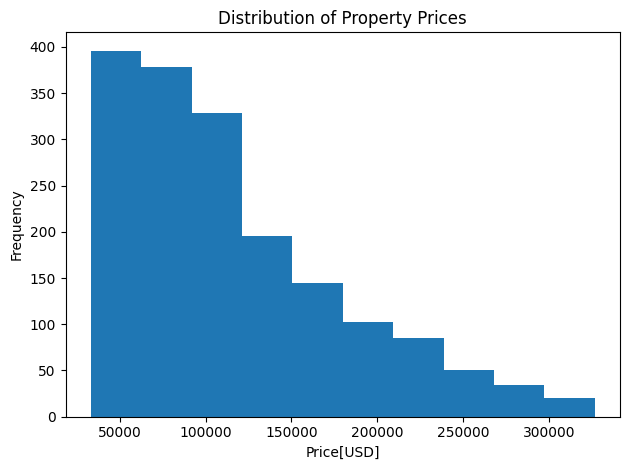

In [5]:
# Create the canvas and the plot area
fig , ax = plt.subplots() 

# Create a histogram for price_usd
ax.hist(df['price_usd'] , bins = 10)

# Add x-axis label, y-axis label & title
ax.set_title("Distribution of Property Prices");
ax.set_xlabel("Price[USD]")
ax.set_ylabel("Frequency")

# Display the graph
plt.tight_layout() # Prevent labels from being cut off
plt.show() # Render the figure

>> The distribution is strongly right-skewed (positively skewed). The tallest bars are on the left — most properties are priced between 30,000 and 130,000. The distribution then tapers off slowly to the right, with a long thin tail of expensive properties extending to 300,000+.

> Histogram for area:

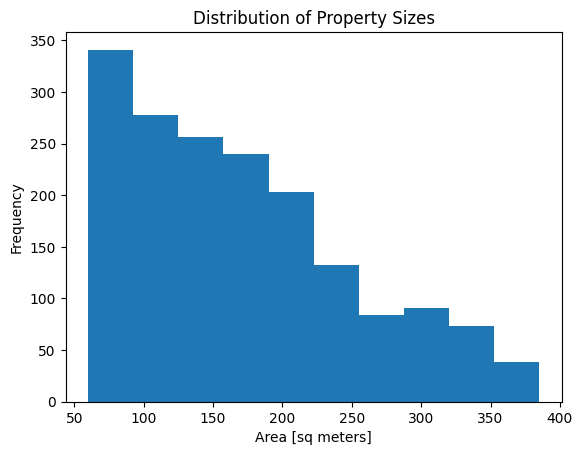

In [6]:
# Create a histogram for area_m2
fig, ax = plt.subplots()

# Use Matplotlib to create histogram of "area_m2"
ax.hist(df["area_m2"])

# Add x-axis label, y-axis label & title
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Property Sizes");

>> Also right-skewed, but for a different reason. Most properties in the dataset are apartments or smaller houses (50–150 m²), with a long tail of larger properties.

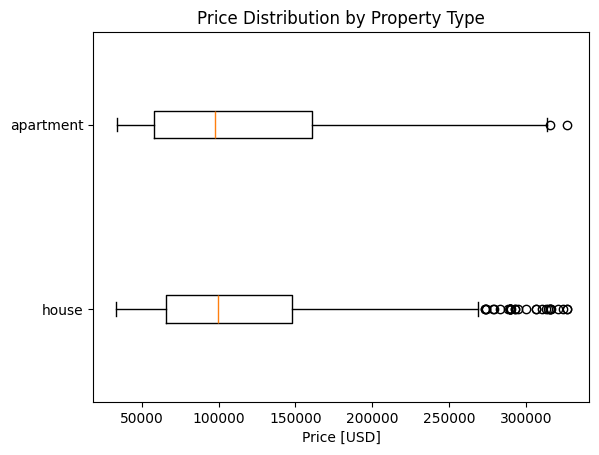

In [7]:
# 1. Get the unique category names on the column "property_type"
prop_types = df['property_type'].unique()

# 2. Prepare the data: Create a list of price arrays, one for each type
data_by_type = [df[df["property_type"] == label]["price_usd"] for label in prop_types]

# 3. Plot
fig, ax = plt.subplots()

# Pass the data list and the labels list
ax.boxplot(data_by_type, tick_labels=prop_types, vert=False)

ax.set_title("Price Distribution by Property Type")
ax.set_xlabel("Price [USD]")


plt.show() # plt.show() acts as the semi-colon, to suppress some ugly text and just give us the graphic.

> **Houses:**
> - Read the median line and the two box edges off your own plot: they give you the
>   typical house price and the range covered by the middle 50% of listings.
> - Notice the **string of outlier dots on the right** — expensive houses extending
>   well past the upper fence. These are the luxury single-family homes that drive
>   the right skew we saw in the histogram.
>
> **Apartments:**
> - The median line sits close to the one for houses, confirming that the *typical*
>   price for both property types is similar.
> - The outlier tail is smaller: fewer dots sit beyond the upper fence.

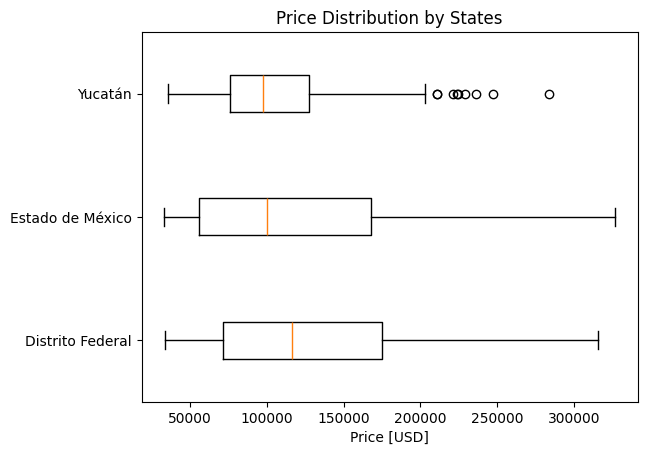

In [14]:
# 1. Define your selected states
selected_states = (
    df["state"]
    .value_counts()
    .head(3)
    .index.tolist()
)
# 2. Prepare the data
data_by_state = [df[df['state'] == state]["price_usd"] for state in selected_states]

# 3. Plot
fig, ax = plt.subplots()

# FIX: Use 'tick_labels' instead of 'labels'
ax.boxplot(data_by_state, tick_labels=selected_states, vert=False)

ax.set_title('Price Distribution by States')
ax.set_xlabel('Price [USD]')
plt.show()

> Distrito Federal: Highest median, indicating the most expensive typical property prices. Long right whisker suggests higher prices are more spread out.

> Estado de México: Lower median than Distrito Federal, but still has some high-value properties.

> Yucatán: Lowest median and narrowest box, indicating more affordable and consistent prices. Right-side outliers suggest a small luxury property segment.

> Property prices vary across states, suggesting that location matters. Two properties with the same area may have different prices depending on their location. This is known as the location effect.

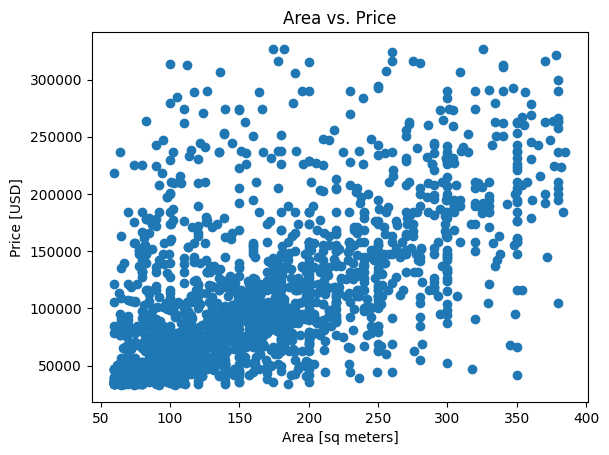

In [15]:
# 1. Create the Figure and Axes objects
fig, ax = plt.subplots()

# 2. Plot on the specific axes object
ax.scatter(x=df["area_m2"], y=df["price_usd"])

# 3. Set labels and title (Note the "set_" prefix)
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price")

plt.show()

> Look at where the points sit. Most of them crowd toward the lower left, while a thinner tail of larger and more expensive properties stretches to the right and upward. This is the signature of outliers compressing the visualization

Original: 1736 rows
Cleaned: 1365 rows
Removed: 371 rows


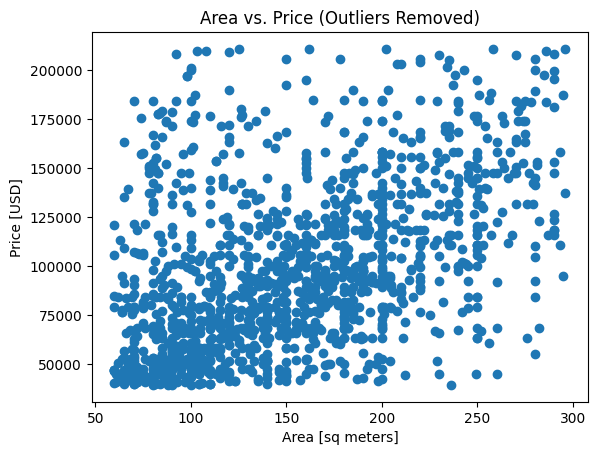

In [16]:
# Define cutoff percentages
lower_cut = 0.05  # Remove bottom 5%
upper_cut = 0.90  # Keep up to 90th percentile

# Filter the data
df_clean = (
    df[
        (df["price_usd"] > df["price_usd"].quantile(lower_cut)) &
        (df["price_usd"] < df["price_usd"].quantile(upper_cut)) &
        (df["area_m2"] < df["area_m2"].quantile(upper_cut)) # <-- Large area outliers also skew the scatter plot
    ]
)

# Show what changed
print(f"Original: {len(df)} rows")
print(f"Cleaned: {len(df_clean)} rows")
print(f"Removed: {len(df) - len(df_clean)} rows")

# Plot
fig, ax = plt.subplots()
ax.scatter(df_clean["area_m2"], df_clean["price_usd"])
ax.set_xlabel("Area [sq meters]")
ax.set_ylabel("Price [USD]")
ax.set_title("Area vs. Price (Outliers Removed)")
plt.show()

> Positive relationship: as area increases, price tends to increase.

> Significant scatter: the cloud is wide, not narrow. Pick any area on the x-axis and look at the vertical spread of prices above it: properties of the same size sell across a broad range. This tells us that area alone does not fully explain price. Something else matters (location? property type?).
 
> No obvious curve: the relationship looks roughly linear in this range, which makes Pearson correlation an appropriate measure.

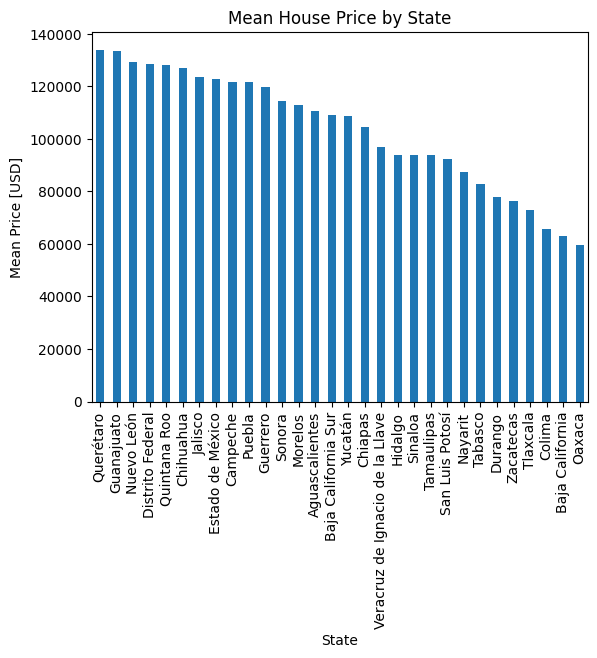

In [20]:
# Aggregate data using groupby
mean_price_by_state = (
    df.groupby("state")["price_usd"]  
    .mean()
    .sort_values(ascending=False) # From highest to lowest
)

# Create figure and axes explicitly
fig, ax = plt.subplots()

# Use pandas plot method with explicit axes
mean_price_by_state.plot(
    kind="bar",
    ax=ax  # Pass the axes to pandas
)

# Customize using Matplotlib methods
ax.set_xlabel("State")
ax.set_ylabel("Mean Price [USD]")
ax.set_title("Mean House Price by State")

plt.show()

> The bar chart shows Distrito Federal with the tallest bar (highest mean price), with other states arranged from highest to lowest. This confirms the location effect: geography matters.

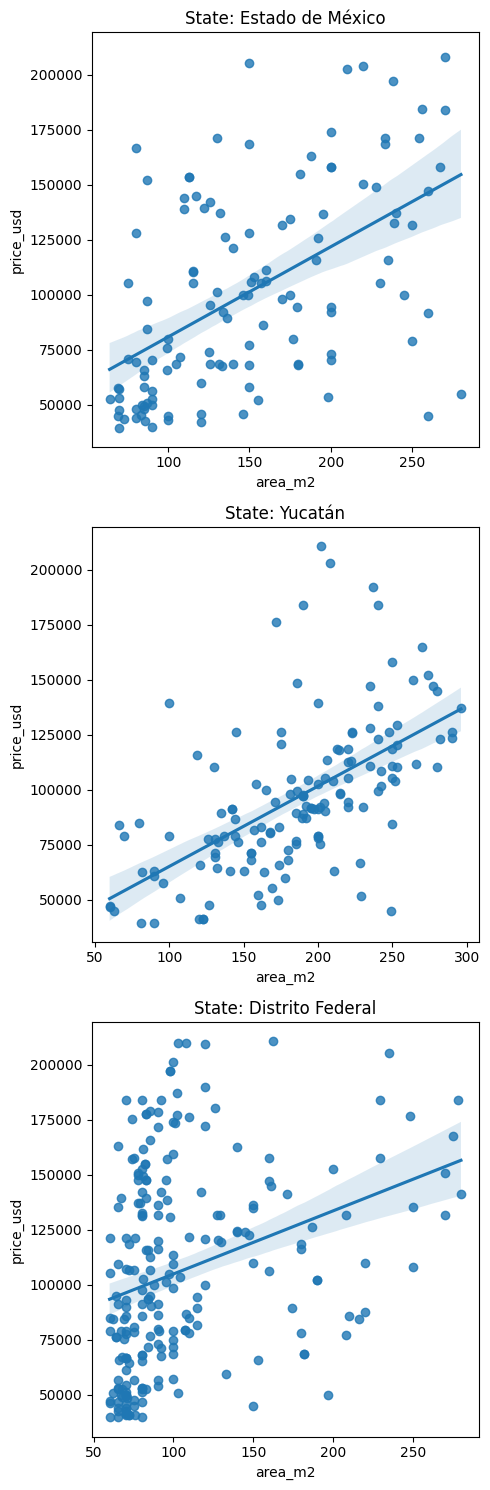

In [24]:
## 1. Create your custom figure and axes
fig, axes = plt.subplots(3, 1, figsize=(5, 15), sharey=True)

# 2. Create a list of the top 3 states
top_states = selected_states 

# 3. Filter df_clean to include only these states
df_states = df_clean[df_clean["state"].isin(top_states)]

# 4. Loop through the states and plot on each specific axis
states = df_states["state"].unique()

for ax, state in zip(axes, states):
    # Filter data for the current state
    subset = df_states[df_states["state"] == state]
    
    # Use regplot (Axes-level) which ACCEPTS 'ax='
    sns.regplot(
        data=subset,
        x="area_m2",  
        y="price_usd",   
        color='tab:blue', # Optional: keep colors consistent
        ax=ax # <--- This is where you pass the axis explicitly
    )
    
    ax.set_title(f"State: {state}")

plt.tight_layout()
plt.show()

**Estado de México — moderate positive relationship:**

- The regression line rises at a clear angle — area does predict price here.
- Wide confidence band — the relationship is real but imprecise. Many properties
  deviate substantially from the line.
- Several high-price properties sit well above the line, suggesting other factors
  (proximity to Mexico City? Specific neighborhoods?) drive premiums.

**Yucatán — strongest and most consistent relationship:**

- Narrow confidence band — the regression line is estimated with high precision.
  The relationship between size and price is more predictable here than in the
  other two states.
- Points cluster more tightly around the line.
- Interpretation: in Yucatán, size is a stronger predictor of price than elsewhere.

**Distrito Federal — weakest relationship:**

- Notice the **compression on the x-axis** — most properties cluster between
  60–120 m². In Mexico City, land is expensive and apartments dominate, so large
  properties are genuinely rare.
- The regression line is nearly flat, and the confidence band is wide — size
  barely explains price in Distrito Federal.
- Interpretation: in Mexico City, **price depends more on location within the city
  (neighborhood, floor, view, proximity to transit) than on raw size.** A 100 m²
  apartment in Polanco is worth far more than a 100 m² apartment in the periphery.


### Conclusion: Location affects not only property prices but also how strongly property size predicts price.